# Walmart: cost-based local subgroups, BS vs BUS vs BUS→BS ensemble, with pruning
Records = Store × Dept weekly sales series (identifiers only). Target = 143-week excess over
peer-expected sales (same department in other stores). Descriptors = store attributes only
(weekly external variables summarised as level / trend / volatility, plus Type, Size, markdowns).
Results are written to `results/walmart_*.csv` and compared with Favorita in `compare_cost_ensemble.ipynb`.

In [1]:
import os
import time
import heapq
import itertools
from collections import Counter

import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [2]:
DATASET = "walmart"
QUICK = False          # True = tiny permutation / scaling runs, only to test the notebook end to end

# ---- Search parameters (Bart §6.3.1) ----
D_MAX = 3                # max conditions in a description
Q = 20                   # result set size
W = 50                   # beam width (BS and the BS step of the hybrid)
U = 200                  # number of mini-clusters (pairs) for every BUS variant
POOL_SIZE = 30           # hybrid: conditions the BS step may use

# ---- Narrow findings ----
# Konijn-style money measures grow with subgroup size, so we cap coverage and
# require at least two stores (a single odd store is not a "pattern").
MIN_COV = 0.02           # at least 2% of records
MAX_COV = 0.15           # at most 15% of records
MIN_STORES = 2

# ---- Reference point (peer-expected sales) ----
BASE_LEN = 52          # length of the base window = one full season cycle
MIN_BASE_LEVEL = 500    # minimum normal sales per week in the base window ($)
MIN_PEERS = 5            # at least 5 records of the same item (dept / family) to build a peer index
UNIT = "$"

# ---- Experiments ----
MEASURES = ["M1", "M2", "M3"]
METHODS = ["BS", "BUS", "BUS-α", "BUS→BS"]
NU = 10 if QUICK else 100                                   # permutation runs for the DFD
SCALING_FRACTIONS = [0.25, 1.0] if QUICK else [0.25, 0.5, 0.75, 1.0]
SCALING_SEEDS = [0] if QUICK else [0, 1, 2]
SEED = 0

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

In [3]:
# Records = the Store–Dept series kept by the preprocessing (complete, 143 weeks).
final = pd.read_csv("final_walmart_data.csv", usecols=["Store", "Dept", "Date"], parse_dates=["Date"])
record_index = final[["Store", "Dept"]].drop_duplicates().sort_values(["Store", "Dept"])
dates = pd.DatetimeIndex(sorted(final["Date"].unique()))

# Raw dollars (the standardised target has no money left in it).
train = pd.read_csv("Walmart/train.csv", parse_dates=["Date"])
sales = (
    train[train["Weekly_Sales"] >= 0]
    .pivot(index=["Store", "Dept"], columns="Date", values="Weekly_Sales")
    .reindex(index=pd.MultiIndex.from_frame(record_index), columns=dates)
    .interpolate(axis=1, limit_area="inside")
)
assert sales.notna().all().all()
S = sales.to_numpy(dtype=float)
records = record_index.rename(columns={"Store": "store", "Dept": "item"}).reset_index(drop=True)

# Store descriptors: weekly external variables -> level, trend (per year), volatility (around the trend).
features = pd.read_csv("Walmart/features.csv", parse_dates=["Date"])
features = features[features["Date"].between(dates[0], dates[-1])].sort_values(["Store", "Date"])
stores = pd.read_csv("Walmart/stores.csv")


def summarise(values, per_year):
    y = values.to_numpy(dtype=float)
    t = np.arange(len(y))
    slope, intercept = np.polyfit(t, y, 1)
    return pd.Series({"mean": y.mean(), "slope": slope * per_year, "volatility": (y - (slope * t + intercept)).std()})


store_desc = []
for variable in ["Temperature", "Fuel_Price", "CPI", "Unemployment"]:
    summary = features.groupby("Store")[variable].apply(summarise, per_year=52).unstack()
    summary.columns = [f"{variable}_{c}" for c in summary.columns]
    store_desc.append(summary)
store_desc = pd.concat(store_desc, axis=1)

md_cols = [f"MarkDown{i}" for i in range(1, 6)]
md_period = features[features["Date"] >= features.loc[features[md_cols].notna().any(axis=1), "Date"].min()]
md_weekly_total = md_period[md_cols].fillna(0).sum(axis=1).groupby(md_period["Store"]).mean()
store_desc = store_desc.join(stores.set_index("Store")[["Type", "Size"]])
store_desc["MarkDown_per_sqft"] = md_weekly_total / store_desc["Size"]

records = records.merge(store_desc, left_on="store", right_index=True, how="left")

categorical_cols = ["Type"]
continuous_cols = [c for c in store_desc.columns if c != "Type"]
peer_relative_cols = []          # Walmart has no record-level descriptors besides the identifiers
print(S.shape, records.shape)

(2733, 143) (2733, 17)


## Reference point: peer-expected sales
For record *i* (a store's item: Walmart department / Favorita product family):

- **level_i** = its normal sales per period in the base window (Konijn's cost *c*).
- **peer index** = how the *same item in the other stores* moved, relative to their own normal level
  (leave-one-out, so a record is never compared with itself).
- **expected_i(t)** = level_i × peer index(t): what this record would have sold had it moved exactly like its peers.
- **e_i(t) = actual − expected**: the continuous, high-dimensional version of Konijn's *c · t*.
- **r_i(t) = e_i(t) / level_i**: the continuous version of the 0/1 target *t* (deviation as a share of own size).

Seasonality and product mix are inside the peer index, so they cancel out. Over the base window the
excess of every record sums to exactly 0, so anything that builds up afterwards is growth or decline
against peers, and anything inside the base window is a timing difference.

In [4]:
level = S[:, :BASE_LEN].mean(axis=1)
item = records["item"].astype(str).to_numpy()

# Keep records with a meaningful size and enough peers.
ok = level >= MIN_BASE_LEVEL
ok &= pd.Series(ok).groupby(item).transform("sum").to_numpy() >= MIN_PEERS

records = records[ok].reset_index(drop=True)
S, level, item = S[ok], level[ok], item[ok]
N, T = S.shape

# Leave-one-out peer index of the same item in the other stores.
group_sales = pd.DataFrame(S).groupby(item).transform("sum").to_numpy()
group_level = pd.Series(level).groupby(item).transform("sum").to_numpy()
peer_index = (group_sales - S) / (group_level - level)[:, None]

expected = level[:, None] * peer_index
excess = S - expected                                  # e_i(t), in UNIT per period
rel_dev = np.clip(excess / level[:, None], -3, 3)      # r_i(t), clipped at ±300%

store_codes = pd.factorize(records["store"])[0]

print(f"{DATASET}: N = {N} records, T = {T} periods, {records['store'].nunique()} stores, "
      f"{records['item'].nunique()} items")
print(f"Base-window excess per record (0 by construction): max |.| = "
      f"{np.abs(excess[:, :BASE_LEN].sum(axis=1)).max():.6f}")

walmart: N = 2566 records, T = 143 periods, 45 stores, 70 items
Base-window excess per record (0 by construction): max |.| = 0.000000


## Descriptors
Store and item are **row identifiers only**; they never appear in descriptions.
Numeric descriptors are z-discretized globally into five bins (Bart §6.3.1).
Peer-relative descriptors are z-scored *within the same item* first ("this store promotes this family
more than other stores do"), so they describe a local difference, not the item itself.

In [5]:
LABELS = ["very_low", "low", "medium", "high", "very_high"]


def z_bins(z):
    return pd.cut(z, bins=[-np.inf, -1.5, -0.5, 0.5, 1.5, np.inf], labels=LABELS).astype(str)


for column in continuous_cols:
    values = records[column]
    records[f"{column}_cat"] = z_bins((values - values.mean()) / values.std())

for column in peer_relative_cols:
    grouped = records.groupby("item")[column]
    z = (records[column] - grouped.transform("mean")) / grouped.transform("std").replace(0, np.nan)
    records[f"{column}_vs_peers_cat"] = z_bins(z.fillna(0))

store_level_desc_cols = categorical_cols + [f"{c}_cat" for c in continuous_cols]
record_level_desc_cols = [f"{c}_vs_peers_cat" for c in peer_relative_cols]
descriptor_cols = store_level_desc_cols + record_level_desc_cols

A = records[descriptor_cols].astype(str).to_numpy(dtype=object)


def describe(desc):
    return " AND ".join(f"{descriptor_cols[j]} = {v}" for j, v in desc)


print(f"{len(descriptor_cols)} descriptors:", descriptor_cols)
records[descriptor_cols].apply(lambda s: s.nunique()).rename("distinct values").to_frame().T

15 descriptors: ['Type', 'Temperature_mean_cat', 'Temperature_slope_cat', 'Temperature_volatility_cat', 'Fuel_Price_mean_cat', 'Fuel_Price_slope_cat', 'Fuel_Price_volatility_cat', 'CPI_mean_cat', 'CPI_slope_cat', 'CPI_volatility_cat', 'Unemployment_mean_cat', 'Unemployment_slope_cat', 'Unemployment_volatility_cat', 'Size_cat', 'MarkDown_per_sqft_cat']


,Type,Temperature_mean_cat,Temperature_slope_cat,Temperature_volatility_cat,Fuel_Price_mean_cat,Fuel_Price_slope_cat,Fuel_Price_volatility_cat,CPI_mean_cat,CPI_slope_cat,CPI_volatility_cat,Unemployment_mean_cat,Unemployment_slope_cat,Unemployment_volatility_cat,Size_cat,MarkDown_per_sqft_cat
distinct values,3,5,5,4,4,4,5,3,3,3,5,5,4,4,5


## Quality measures (Konijn et al. → continuous, high-dimensional target)
| | Konijn (fraud) | here |
|---|---|---|
| target *t* | 0/1: patient of the dentist? | *r_i(t)*: deviation from peers each period |
| cost *c* | € per patient | *level_i*: normal sales per period |
| *c · t* | | *e_i(t)* = actual − expected |
| **M1** | MVPCD (eq. 6): money beyond expectation | Σ over subgroup and periods of *e_i(t)* |
| **M2** | Relative CWTPD (eq. 2): also subtract what happens outside | M1 minus what the rest did at the same scale |
| **M3** | (Bart) φ_cluster | α/(β+1) on the *r_i* curves: shape of the deviation |

**Pruning support.** Every measure knows two kinds of constraints:
- *anti-monotone* (min coverage, min stores): if a subgroup fails, every refinement fails too, so it
  is never refined (coverage pruning);
- *monotone* (max coverage): a too-large subgroup can still have valid refinements, so it is
  evaluated and may be refined, but never reported.

M1 and M2 also have an exact **optimistic estimate**: the best |quality| any refinement (subset) of a
subgroup could reach. If that bound is below the current q-th best result, the whole branch is pruned.
- M1: a subset can at most keep all positive excess or all negative excess:
  OE = max(Σ positive x_i, Σ |negative x_i|).
- M2 can be rewritten as (L_T / (L_T − L_S)) · Σ_{i∈S} y_i with y_i = x_i − level_i · X_T / L_T.
  For a subset the factor can only shrink, so OE = max(Σ y⁺, Σ |y⁻|) · L_T / (L_T − L_S).
- M3 (φ_cluster) has no cheap bound, so only coverage and redundancy pruning apply.

In [6]:
class QualityBase:
    """Caching, constraints and the pruning interface shared by every measure."""

    def __init__(self, N, store_codes, min_cov=None, max_cov=None, min_stores=None):
        min_cov = MIN_COV if min_cov is None else min_cov
        max_cov = MAX_COV if max_cov is None else max_cov
        self.N = N
        self.store_codes = store_codes
        self.n_store_codes = int(store_codes.max()) + 1
        self.min_n = max(2, int(np.ceil(min_cov * N)))
        self.max_n = int(np.floor(max_cov * N))
        self.min_stores = MIN_STORES if min_stores is None else min_stores
        self.cache = {}

    def n_stores(self, mask):
        return np.count_nonzero(np.bincount(self.store_codes[mask], minlength=self.n_store_codes))

    def expandable(self, mask):
        """Anti-monotone constraints: failing them means no refinement can pass either."""
        return mask.sum() >= self.min_n and self.n_stores(mask) >= self.min_stores

    def satisfies_constraints(self, mask):
        n = mask.sum()
        return n <= self.max_n and n < self.N and self.expandable(mask)

    def optimistic_estimate(self, mask):
        return None

    def __call__(self, mask):
        key = mask.tobytes()
        if key not in self.cache:
            self.cache[key] = self.compute(mask)
        return self.cache[key]


class MonetaryQuality(QualityBase):
    """M1 (relative=False): MVPCD analogue, sum of excess.
    M2 (relative=True): Relative CWTPD analogue, excess beyond what the rest did at the same scale.
    Ranked by |value|; signed() keeps the direction (+ outperform, - underperform)."""

    def __init__(self, excess, level, store_codes, relative=True, **constraints):
        super().__init__(len(level), store_codes, **constraints)
        self.relative = relative
        self.x = excess.sum(axis=1)
        self.level = level
        self.L_T = level.sum()
        self.y = self.x - level * self.x.sum() / self.L_T

    def signed(self, mask):
        if not self.relative:
            return self.x[mask].sum()
        return self.y[mask].sum() * self.L_T / (self.L_T - self.level[mask].sum())

    def compute(self, mask):
        return abs(self.signed(mask))

    def optimistic_estimate(self, mask):
        v = self.y[mask] if self.relative else self.x[mask]
        bound = max(v[v > 0].sum(), -v[v < 0].sum())
        if self.relative:
            bound *= self.L_T / (self.L_T - self.level[mask].sum())
        return bound


class ClusterQuality(QualityBase):
    """M3: Bart's phi_cluster = alpha / (beta + 1) on a precomputed distance matrix."""

    def __init__(self, D, store_codes, **constraints):
        super().__init__(len(D), store_codes, **constraints)
        self.D = D
        self.rowsum = D.sum(axis=1)

    def components(self, mask):
        idx = np.flatnonzero(mask)
        n, n_c = len(idx), self.N - len(idx)
        within = self.D[np.ix_(idx, idx)].sum()
        between = self.rowsum[idx].sum() - within
        return between / (n * n_c), within / (n * (n - 1))

    def compute(self, mask):
        alpha, beta = self.components(mask)
        return alpha / (beta + 1)


# Distance matrices on the target, built once (the only step whose cost depends on T).
start = time.time()
D_money = cdist(excess, excess, metric="cityblock")    # excess curves: pick mini-clusters for M1/M2
D_shape = cdist(rel_dev, rel_dev, metric="cityblock")  # relative deviation curves: M3 and its mini-clusters
DISTANCE_TIME = time.time() - start
DISTANCE_FOR = {"M1": D_money, "M2": D_money, "M3": D_shape}
print(f"Distance matrices ({N} x {N}, T = {T}) built in {DISTANCE_TIME:.1f}s")


def make_quality(measure, idx=None):
    idx = np.arange(N) if idx is None else idx
    if measure == "M1":
        return MonetaryQuality(excess[idx], level[idx], store_codes[idx], relative=False)
    if measure == "M2":
        return MonetaryQuality(excess[idx], level[idx], store_codes[idx], relative=True)
    return ClusterQuality(D_shape[np.ix_(idx, idx)], store_codes[idx])


# Sanity check: the rewritten M2 equals the direct definition.
_phi = make_quality("M2")
_mask = np.zeros(N, dtype=bool)
_mask[: N // 10] = True
_direct = _phi.x[_mask].sum() - level[_mask].sum() * (_phi.x.sum() - _phi.x[_mask].sum()) / (level.sum() - level[_mask].sum())
assert np.isclose(_phi.signed(_mask), _direct)

Distance matrices (2566 x 2566, T = 143) built in 1.5s


## Search strategies (each with `prune=False` / `prune=True`)
| method | candidates come from | Bart / ours |
|---|---|---|
| **BS** | refinement operator η over all conditions | Alg. 1, §2.3 |
| **BUS** | the u *closest* pairs in D (plain BUSPaS) | Alg. 2 + 3 |
| **BUS-α** | the u pairs with the best α/(D+1): similar *and* unusual | §4.3.2 α-matrix |
| **BUS→BS** | BUS-α pairs vote for conditions → top POOL_SIZE → beam search over that pool | ensemble |

**Pruning (`prune=True`):**
1. *Coverage pruning:* a description failing an anti-monotone constraint is never refined (BS) and
   all its supersets are skipped without computing them (BUS variants, Apriori-style).
2. *Optimistic-estimate pruning (M1, M2):* once the result set is full, a subgroup whose OE is below
   the q-th best result is not refined (BS) and its supersets are skipped (BUS). This is exact for the
   BUS variants. In BS it frees beam slots for promising candidates, so BS results can only change
   by finding *other* good subgroups.
3. *Redundancy pruning:* a refinement that does not change the subgroup (same records) is dropped.

Without pruning, descriptions failing min coverage / min stores are still skipped, exactly as before
(those are Alg. 1's constraints), but every other candidate is evaluated.

In [7]:
def mask_of(A, desc):
    mask = np.ones(len(A), dtype=bool)
    for j, v in desc:
        mask &= A[:, j] == v
    return mask


class ResultSet:
    """PriorityQueue(q). Re-descriptions (same records) are kept once, with the shortest description."""

    def __init__(self, q):
        self.q = q
        self.items = {}

    def insert(self, quality, desc, mask):
        key = mask.tobytes()
        old = self.items.get(key)
        if old is not None and len(old[1]) <= len(desc):
            return
        self.items[key] = (quality, desc, mask)
        if len(self.items) > self.q:
            del self.items[min(self.items, key=lambda k: self.items[k][0])]

    def full(self):
        return len(self.items) >= self.q

    def threshold(self):
        return min(v[0] for v in self.items.values()) if self.full() else -np.inf

    def sorted(self):
        return sorted(self.items.values(), key=lambda x: -x[0])


def oe_below_threshold(phi, mask, result_set):
    if not result_set.full():
        return False
    oe = phi.optimistic_estimate(mask)
    return oe is not None and oe < result_set.threshold()


# ---------------------------------------------------------------- Beam search (Alg. 1)
def refine(seed, seed_mask, A, pool=None):
    """eta: one extra condition on an unused attribute, only with values still present in the seed's
    subgroup (§2.3). With a pool (hybrid), only pool conditions are allowed."""
    used = {j for j, _ in seed}
    if pool is None:
        options = ((j, v) for j in range(A.shape[1]) if j not in used for v in pd.unique(A[seed_mask, j]))
    else:
        options = ((j, v) for j, v in pool if j not in used and (A[seed_mask, j] == v).any())
    for condition in options:
        yield tuple(sorted(seed + (condition,), key=lambda c: c[0]))


def beam_search(A, phi, w=W, d=D_MAX, q=Q, prune=False, pool=None):
    stats = Counter()
    result_set = ResultSet(q)
    candidate_queue = [()]
    seen, tie = set(), itertools.count()

    for level_ in range(1, d + 1):
        beam = []
        for seed in candidate_queue:
            seed_mask = mask_of(A, seed)
            if prune and seed and oe_below_threshold(phi, seed_mask, result_set):
                stats["pruned_oe_seed"] += 1          # no refinement of this seed can reach the top-q
                continue
            for desc in refine(seed, seed_mask, A, pool):
                if desc in seen:
                    continue
                seen.add(desc)
                stats["generated"] += 1
                mask = mask_of(A, desc)
                if not phi.expandable(mask):
                    stats["skipped_coverage"] += 1    # Alg. 1 constraint, also without pruning
                    continue
                if prune and seed and mask.sum() == seed_mask.sum():
                    stats["pruned_redundant"] += 1    # extra condition removes no record
                    continue
                quality = phi(mask)
                stats["evaluated"] += 1
                if phi.satisfies_constraints(mask):
                    result_set.insert(quality, desc, mask)
                if prune and oe_below_threshold(phi, mask, result_set):
                    stats["pruned_oe"] += 1           # keep it out of the beam: its subtree is useless
                    continue
                item_ = (quality, next(tie), desc)
                if len(beam) < w:
                    heapq.heappush(beam, item_)
                else:
                    heapq.heappushpop(beam, item_)
        candidate_queue = [desc for _, _, desc in sorted(beam, reverse=True)]

    return result_set.sorted(), stats


# ---------------------------------------------------------------- Mini-clusters
_tril = {}


def tril(N):
    if N not in _tril:
        _tril[N] = np.tril_indices(N, -1)
    return _tril[N]


def closest_pairs(D, u=U):
    """Plain BUS (Alg. 2, find_min_indices): the u smallest distances."""
    rows, cols = tril(len(D))
    d = D[rows, cols]
    best = np.argpartition(d, u)[:u]
    best = best[np.argsort(d[best])]
    return [(int(rows[b]), int(cols[b])) for b in best]


def alpha_pairs(D, u=U):
    """alpha-matrix (§4.3.2): score = alpha_ij / (D_ij + 1), close to each other AND far from the rest."""
    N_ = len(D)
    rows, cols = tril(N_)
    rowsum = D.sum(axis=1)
    d = D[rows, cols]
    alpha = (rowsum[rows] + rowsum[cols] - 2 * d) / (2 * (N_ - 2))
    score = alpha / (d + 1)
    best = np.argpartition(-score, u)[:u]
    best = best[np.argsort(-score[best])]
    return [(int(rows[b]), int(cols[b])) for b in best]


def shared_conditions(mc, A):
    """Alg. 3: descriptor values shared by every record in the mini-cluster."""
    first = mc[0]
    return [(j, A[first, j]) for j in range(A.shape[1]) if all(A[i, j] == A[first, j] for i in mc)]


# ---------------------------------------------------------------- Bottom-up search (Alg. 2)
def evaluate_candidates(A, phi, candidates, q=Q, prune=False):
    """Evaluate BUS candidates, shortest first. With pruning, supersets of a 'dead' description
    (failed coverage, or OE below the q-th best) are skipped without being computed."""
    stats = Counter(candidates=len(candidates))
    result_set = ResultSet(q)
    dead = set()
    for desc in sorted(candidates, key=len):
        if prune and len(desc) > 1 and any(
            sub in dead for size in range(1, len(desc)) for sub in itertools.combinations(desc, size)
        ):
            stats["pruned_superset"] += 1
            continue
        mask = mask_of(A, desc)
        if not phi.expandable(mask):
            stats["skipped_coverage"] += 1
            dead.add(desc)
            continue
        quality = phi(mask)
        stats["evaluated"] += 1
        if phi.satisfies_constraints(mask):
            result_set.insert(quality, desc, mask)
        if prune and oe_below_threshold(phi, mask, result_set):
            dead.add(desc)
    return result_set.sorted(), stats


def bus(A, phi, pairs, d=D_MAX, q=Q, prune=False):
    candidates = set()
    for mc in pairs:
        conditions = shared_conditions(mc, A)
        for size in range(1, d + 1):
            candidates.update(itertools.combinations(conditions, size))
    return evaluate_candidates(A, phi, candidates, q, prune)


# ---------------------------------------------------------------- Ensemble BUS -> BS
def hybrid(A, phi, pairs, pool_size=POOL_SIZE, prune=False):
    """BUS decides WHERE to look (conditions shared by pairs that deviate together),
    BS decides HOW to combine them (beam search restricted to that pool)."""
    votes = Counter(c for mc in pairs for c in shared_conditions(mc, A))
    pool = [c for c, _ in votes.most_common(pool_size)]
    top, stats = beam_search(A, phi, prune=prune, pool=pool)
    stats["pool"] = len(pool)
    return top, stats, pool


def run_method(method, A, phi, D, prune, pairs=None):
    """Runs one search. Mini-cluster selection time is included in the runtime (it is part of BUS)."""
    start = time.time()
    pool = None
    if method == "BS":
        top, stats = beam_search(A, phi, prune=prune)
    else:
        if pairs is None:
            pairs = closest_pairs(D) if method == "BUS" else alpha_pairs(D)
        stats_pairs_time = time.time() - start
        if method in ("BUS", "BUS-α"):
            top, stats = bus(A, phi, pairs, prune=prune)
        else:
            top, stats, pool = hybrid(A, phi, pairs, prune=prune)
        stats["pair_time"] = stats_pairs_time
    stats["runtime"] = time.time() - start
    return top, stats, pool


def top_keys(top):
    return {m.tobytes() for _, _, m in top}


def jaccard(a, b):
    return len(a & b) / len(a | b) if a | b else 1.0

## Experiment 1: every measure × every search × pruning off/on
For each measure, unpruned BS is the reference. Columns:
- `evaluated`: quality computations (the expensive part); `generated`: candidate descriptions built;
- `best`, `avg`: best and average quality of the top-q;
- `jaccard_vs_BS`, `shared_vs_BS`: overlap of the top-q subgroups with unpruned BS (same records);
- `pool_recall` (hybrid only): share of the conditions used in BS's top-q that made it into the pool.
  This checks whether the BUS voting step points the beam search in the right direction.

In [8]:
main_rows, main_runs = [], {}
for measure in MEASURES:
    D = DISTANCE_FOR[measure]
    for method in METHODS:
        for prune in (False, True):
            phi = make_quality(measure)
            top, stats, pool = run_method(method, A, phi, D, prune)
            main_runs[(measure, method, prune)] = (top, stats, pool, phi)

    reference = top_keys(main_runs[(measure, "BS", False)][0])
    bs_conditions = {c for _, desc, _ in main_runs[(measure, "BS", False)][0] for c in desc}
    for method in METHODS:
        for prune in (False, True):
            top, stats, pool, phi = main_runs[(measure, method, prune)]
            qualities = np.array([q for q, _, _ in top]) if top else np.array([np.nan])
            keys = top_keys(top)
            main_rows.append({
                "dataset": DATASET, "N": N, "T": T, "measure": measure, "method": method, "prune": prune,
                "runtime_s": stats["runtime"], "pair_time_s": stats.get("pair_time", 0.0),
                "generated": stats.get("generated", stats.get("candidates", 0)),
                "evaluated": stats["evaluated"],
                "pruned": sum(v for k, v in stats.items() if k.startswith("pruned")),
                "best": qualities.max(), "avg": qualities.mean(), "n_results": len(top),
                "avg_coverage": np.mean([m.mean() for _, _, m in top]) if top else np.nan,
                "jaccard_vs_BS": jaccard(keys, reference), "shared_vs_BS": len(keys & reference),
                "pool_recall": (len(bs_conditions & set(pool)) / len(bs_conditions)) if pool else np.nan,
            })

main_df = pd.DataFrame(main_rows)
main_df.to_csv(f"{RESULTS_DIR}/{DATASET}_main.csv", index=False)
pd.set_option("display.width", 250)
display(main_df.drop(columns=["dataset", "N", "T"]).round(3))

,measure,method,prune,runtime_s,pair_time_s,generated,evaluated,pruned,best,avg,n_results,avg_coverage,jaccard_vs_BS,shared_vs_BS,pool_recall
0,M1,BS,False,0.614,0.000,2626,1974,0,5.252768e+07,4.224634e+07,20,0.127,1.000,20,NaN
1,M1,BS,True,0.672,0.000,2467,1848,1403,5.252768e+07,4.224634e+07,20,0.127,1.000,20,NaN
2,M1,BUS,False,0.999,0.099,3586,3515,0,5.252768e+07,4.181274e+07,20,0.124,0.905,19,NaN
3,M1,BUS,True,0.606,0.062,3586,2310,1274,5.252768e+07,4.181274e+07,20,0.124,0.905,19,NaN
4,M1,BUS-α,False,0.934,0.193,3582,3511,0,5.252768e+07,4.181274e+07,20,0.124,0.905,19,NaN
5,M1,BUS-α,True,0.787,0.208,3582,2309,1271,5.252768e+07,4.181274e+07,20,0.124,0.905,19,NaN
6,M1,BUS→BS,False,0.497,0.162,1248,1146,0,5.252768e+07,4.003055e+07,20,0.120,0.600,15,0.882
7,M1,BUS→BS,True,0.568,0.155,1242,1108,605,5.252768e+07,4.003055e+07,20,0.120,0.600,15,0.882
8,M2,BS,False,0.689,0.000,2729,2068,0,6.350184e+07,4.990778e+07,20,0.129,1.000,20,NaN
9,M2,BS,True,0.716,0.000,2592,1971,1417,6.350184e+07,4.990778e+07,20,0.129,1.000,20,NaN


## The narrow M2 subgroups
`excess` is in the dataset's unit (Walmart: $; Favorita: units sold). `pct_of_normal` relates it to the
subgroup's normal volume over the whole period; `per_record_period` is the average per record and period.

In [9]:
def m2_table(top, phi):
    rows = []
    for rank, (quality, desc, mask) in enumerate(top, start=1):
        signed = phi.signed(mask)
        rows.append({
            "rank": rank, "description": describe(desc),
            f"excess_{UNIT}": signed,
            "pct_of_normal": 100 * signed / (level[mask].sum() * T),
            "per_record_period": signed / (mask.sum() * T),
            "coverage_n": int(mask.sum()), "n_stores": phi.n_stores(mask),
        })
    return pd.DataFrame(rows)


top_tables = []
for method in METHODS:
    top, stats, pool, phi = main_runs[("M2", method, True)]
    table = m2_table(top, phi).assign(method=method)
    top_tables.append(table)
    print(f"\n{method} (pruned)")
    display(table.drop(columns="method").head(10).round(2))


BS (pruned)

BUS (pruned)

BUS-α (pruned)

BUS→BS (pruned)


,rank,description,excess_$,pct_of_normal,per_record_period,coverage_n,n_stores
0,1,Temperature_volatility_cat = medium AND Fuel_P...,-63501837.59,-5.41,-1168.60,380,6
1,2,Temperature_slope_cat = medium AND Unemploymen...,-59537231.38,-4.84,-1092.77,381,6
2,3,Temperature_mean_cat = medium AND Unemployment...,-56609693.27,-5.02,-1237.10,320,5
3,4,Temperature_mean_cat = medium AND Temperature_...,-55991697.53,-6.74,-1553.77,252,4
4,5,Temperature_mean_cat = medium AND Unemployment...,-55270346.43,-4.40,-1009.15,383,6
5,6,Temperature_volatility_cat = medium AND Unempl...,-54708163.56,-5.71,-1214.52,315,5
6,7,Temperature_mean_cat = medium AND Temperature_...,-54687674.12,-5.71,-1206.41,317,5
7,8,Fuel_Price_slope_cat = high AND CPI_volatility...,-54005190.97,-5.27,-1007.09,375,6
8,9,CPI_volatility_cat = low AND Unemployment_mean...,52317731.56,5.43,1045.31,350,6
9,10,Fuel_Price_volatility_cat = medium AND Size_ca...,-47837570.14,-3.76,-1001.58,334,5


,rank,description,excess_$,pct_of_normal,per_record_period,coverage_n,n_stores
0,1,Temperature_volatility_cat = medium AND Fuel_P...,-63501837.59,-5.41,-1168.60,380,6
1,2,Temperature_slope_cat = medium AND Unemploymen...,-59537231.38,-4.84,-1092.77,381,6
2,3,Temperature_mean_cat = medium AND Fuel_Price_v...,-56609693.27,-5.02,-1237.10,320,5
3,4,Temperature_slope_cat = medium AND Temperature...,-55991697.53,-6.74,-1553.77,252,4
4,5,Temperature_mean_cat = medium AND Unemployment...,-55270346.43,-4.40,-1009.15,383,6
5,6,Temperature_volatility_cat = medium AND Unempl...,-54708163.56,-5.71,-1214.52,315,5
6,7,Temperature_mean_cat = medium AND Temperature_...,-54687674.12,-5.71,-1206.41,317,5
7,8,Fuel_Price_volatility_cat = medium AND CPI_mea...,-54005190.97,-5.27,-1007.09,375,6
8,9,Fuel_Price_volatility_cat = medium AND Size_ca...,-47837570.14,-3.76,-1001.58,334,5
9,10,Type = A AND Temperature_volatility_cat = medi...,-47181330.47,-3.70,-926.80,356,6


,rank,description,excess_$,pct_of_normal,per_record_period,coverage_n,n_stores
0,1,Temperature_volatility_cat = medium AND Fuel_P...,-63501837.59,-5.41,-1168.60,380,6
1,2,Temperature_slope_cat = medium AND Unemploymen...,-59537231.38,-4.84,-1092.77,381,6
2,3,Temperature_mean_cat = medium AND Fuel_Price_v...,-56609693.27,-5.02,-1237.10,320,5
3,4,Temperature_slope_cat = medium AND Temperature...,-55991697.53,-6.74,-1553.77,252,4
4,5,Temperature_mean_cat = medium AND Unemployment...,-55270346.43,-4.40,-1009.15,383,6
5,6,Temperature_volatility_cat = medium AND Unempl...,-54708163.56,-5.71,-1214.52,315,5
6,7,Temperature_mean_cat = medium AND Temperature_...,-54687674.12,-5.71,-1206.41,317,5
7,8,Fuel_Price_volatility_cat = medium AND CPI_mea...,-54005190.97,-5.27,-1007.09,375,6
8,9,Fuel_Price_volatility_cat = medium AND Size_ca...,-47837570.14,-3.76,-1001.58,334,5
9,10,Type = A AND Temperature_volatility_cat = medi...,-47181330.47,-3.70,-926.80,356,6


,rank,description,excess_$,pct_of_normal,per_record_period,coverage_n,n_stores
0,1,Temperature_volatility_cat = medium AND Fuel_P...,-63501837.59,-5.41,-1168.60,380,6
1,2,Temperature_slope_cat = medium AND Unemploymen...,-59537231.38,-4.84,-1092.77,381,6
2,3,Temperature_volatility_cat = medium AND Unempl...,-55991697.53,-6.74,-1553.77,252,4
3,4,Temperature_volatility_cat = medium AND Unempl...,-54708163.56,-5.71,-1214.52,315,5
4,5,Fuel_Price_slope_cat = high AND CPI_slope_cat ...,-54005190.97,-5.27,-1007.09,375,6
5,6,Fuel_Price_volatility_cat = medium AND Size_ca...,-47837570.14,-3.76,-1001.58,334,5
6,7,Type = A AND Temperature_volatility_cat = medi...,-47181330.47,-3.70,-926.80,356,6
7,8,Fuel_Price_mean_cat = low AND CPI_volatility_c...,46937873.12,5.27,872.97,376,6
8,9,Unemployment_slope_cat = high AND MarkDown_per...,-45690239.96,-3.87,-974.12,328,5
9,10,Temperature_volatility_cat = medium AND Unempl...,-45027005.00,-3.64,-948.42,332,5


## Experiment 2: significance (store-level permutation DFD, as in cell 32 of the Walmart notebook)
Null: store-level descriptors are handed to a random other store, record-level (peer-relative)
descriptors are shuffled among the records of the same item. The target stays the same, so the
quality object (and its cache) and the mini-cluster pairs are reused. Each method gets its own DFD
(Bart did the same for BS and BUS). M2 with pruning on.

In [10]:
store_table = records.groupby("store")[store_level_desc_cols].first()


def permuted_descriptors(rng):
    perm = records[descriptor_cols].copy()
    donor = dict(zip(store_table.index, rng.permutation(store_table.index)))
    perm[store_level_desc_cols] = store_table.loc[records["store"].map(donor)].to_numpy()
    for column in record_level_desc_cols:
        perm[column] = records.groupby("item")[column].transform(lambda s: rng.permutation(s.to_numpy()))
    return perm.astype(str).to_numpy(dtype=object)


def empirical_p_value(quality, dfd):
    return ((dfd > quality).sum() + 0.5 * (dfd == quality).sum() + 1) / (len(dfd) + 1)


dfd_rows, dfd_by_method = [], {}
pairs_cache = {"BUS": closest_pairs(D_money), "BUS-α": alpha_pairs(D_money)}
pairs_cache["BUS→BS"] = pairs_cache["BUS-α"]
for method in METHODS:
    top, stats, pool, phi = main_runs[("M2", method, True)]
    rng = np.random.default_rng(SEED)
    start = time.time()
    dfd = []
    for _ in range(NU):
        perm_top, _, _ = run_method(method, permuted_descriptors(rng), phi, D_money, True,
                                    pairs=pairs_cache.get(method))
        dfd.append(perm_top[0][0] if perm_top else 0.0)
    dfd = np.array(dfd)
    dfd_by_method[method] = dfd
    p_values = [empirical_p_value(q, dfd) for q, _, _ in top]
    for table in top_tables:
        if table["method"].iloc[0] == method:
            table["p_value"] = p_values
    dfd_rows.append({"dataset": DATASET, "method": method, "nu": NU, "dfd_seconds": time.time() - start,
                     "dfd_median": np.median(dfd), "dfd_95": np.quantile(dfd, 0.95),
                     "best_quality": top[0][0], "n_significant_005": int(np.sum(np.array(p_values) < 0.05))})
    print(f"{method}: DFD in {time.time() - start:.0f}s, {dfd_rows[-1]['n_significant_005']} of {len(top)} with p < 0.05")

dfd_df = pd.DataFrame(dfd_rows)
dfd_df.to_csv(f"{RESULTS_DIR}/{DATASET}_dfd.csv", index=False)
top_df = pd.concat(top_tables).assign(dataset=DATASET)
top_df.to_csv(f"{RESULTS_DIR}/{DATASET}_top_m2.csv", index=False)
display(dfd_df.round(3))
display(top_df[top_df["method"] == "BUS→BS"].head(10).round(3))

BS: DFD in 73s, 1 of 20 with p < 0.05
BUS: DFD in 41s, 1 of 20 with p < 0.05
BUS-α: DFD in 42s, 1 of 20 with p < 0.05
BUS→BS: DFD in 41s, 1 of 20 with p < 0.05


,dataset,method,nu,dfd_seconds,dfd_median,dfd_95,best_quality,n_significant_005
0,walmart,BS,100,73.274,4.841174e+07,6.053017e+07,6.350184e+07,1
1,walmart,BUS,100,41.146,4.664079e+07,6.053017e+07,6.350184e+07,1
2,walmart,BUS-α,100,41.504,4.664079e+07,6.053017e+07,6.350184e+07,1
3,walmart,BUS→BS,100,40.816,4.615505e+07,5.953493e+07,6.350184e+07,1


,rank,description,excess_$,pct_of_normal,per_record_period,coverage_n,n_stores,method,p_value,dataset
0,1,Temperature_volatility_cat = medium AND Fuel_P...,-6.350184e+07,-5.413,-1168.602,380,6,BUS→BS,0.040,walmart
1,2,Temperature_slope_cat = medium AND Unemploymen...,-5.953723e+07,-4.841,-1092.767,381,6,BUS→BS,0.059,walmart
2,3,Temperature_volatility_cat = medium AND Unempl...,-5.599170e+07,-6.743,-1553.771,252,4,BUS→BS,0.119,walmart
3,4,Temperature_volatility_cat = medium AND Unempl...,-5.470816e+07,-5.706,-1214.522,315,5,BUS→BS,0.158,walmart
4,5,Fuel_Price_slope_cat = high AND CPI_slope_cat ...,-5.400519e+07,-5.275,-1007.090,375,6,BUS→BS,0.168,walmart
5,6,Fuel_Price_volatility_cat = medium AND Size_ca...,-4.783757e+07,-3.756,-1001.582,334,5,BUS→BS,0.416,walmart
6,7,Type = A AND Temperature_volatility_cat = medi...,-4.718133e+07,-3.700,-926.796,356,6,BUS→BS,0.436,walmart
7,8,Fuel_Price_mean_cat = low AND CPI_volatility_c...,4.693787e+07,5.275,872.970,376,6,BUS→BS,0.446,walmart
8,9,Unemployment_slope_cat = high AND MarkDown_per...,-4.569024e+07,-3.872,-974.122,328,5,BUS→BS,0.525,walmart
9,10,Temperature_volatility_cat = medium AND Unempl...,-4.502701e+07,-3.638,-948.416,332,5,BUS→BS,0.545,walmart


## Experiment 3: does it matter when there are more records?
Random subsets of the stores (all their records), several seeds per fraction. Distance matrices are
sliced from the full ones, so only the search is timed. M2 (cheap, O(n) per evaluation, exact OE) and
M3 (expensive, O(n²) per evaluation, no OE). For every subset, unpruned BS on that subset is the reference.

In [11]:
scaling_rows = []
all_stores = records["store"].unique()
for fraction in SCALING_FRACTIONS:
    for seed in (SCALING_SEEDS if fraction < 1.0 else [0]):
        rng = np.random.default_rng(seed)
        chosen = rng.choice(all_stores, size=max(MIN_STORES + 2, int(round(fraction * len(all_stores)))), replace=False)
        idx = np.flatnonzero(records["store"].isin(chosen).to_numpy())
        A_sub = A[idx]
        for measure in ("M2", "M3"):
            D_sub = DISTANCE_FOR[measure][np.ix_(idx, idx)]
            runs = {}
            for method in METHODS:
                for prune in (False, True):
                    runs[(method, prune)] = run_method(method, A_sub, make_quality(measure, idx), D_sub, prune)
            reference = top_keys(runs[("BS", False)][0])
            ref_best = runs[("BS", False)][0][0][0] if runs[("BS", False)][0] else np.nan
            for (method, prune), (top, stats, pool) in runs.items():
                scaling_rows.append({
                    "dataset": DATASET, "fraction": fraction, "seed": seed, "N_sub": len(idx),
                    "stores": len(chosen), "measure": measure, "method": method, "prune": prune,
                    "runtime_s": stats["runtime"], "evaluated": stats["evaluated"],
                    "best_vs_BS": (top[0][0] / ref_best) if top else np.nan,
                    "jaccard_vs_BS": jaccard(top_keys(top), reference),
                })
        print(f"fraction {fraction}, seed {seed}: N = {len(idx)} done")

scaling_df = pd.DataFrame(scaling_rows)
scaling_df.to_csv(f"{RESULTS_DIR}/{DATASET}_scaling.csv", index=False)
display(scaling_df.groupby(["measure", "method", "prune", "fraction"])[["N_sub", "runtime_s", "evaluated", "best_vs_BS", "jaccard_vs_BS"]].mean().round(3))

fraction 0.25, seed 0: N = 653 done
fraction 0.25, seed 1: N = 683 done
fraction 0.25, seed 2: N = 588 done
fraction 0.5, seed 0: N = 1302 done
fraction 0.5, seed 1: N = 1326 done
fraction 0.5, seed 2: N = 1248 done
fraction 0.75, seed 0: N = 1951 done
fraction 0.75, seed 1: N = 1895 done
fraction 0.75, seed 2: N = 1916 done
fraction 1.0, seed 0: N = 2566 done


N_sub  runtime_s  ...  best_vs_BS  jaccard_vs_BS
measure method prune fraction                       ...                           
M2      BS     False 0.25       641.333      0.170  ...       1.000          1.000
                     0.50      1292.000      0.309  ...       1.000          1.000
                     0.75      1920.667      0.472  ...       1.000          1.000
                     1.00      2566.000      0.580  ...       1.000          1.000
               True  0.25       641.333      0.167  ...       1.000          1.000
...                                 ...        ...  ...         ...            ...
M3      BUS→BS False 1.00      2566.000      1.059  ...       1.000          0.667
               True  0.25       641.333      0.133  ...       0.981          0.833
                     0.50      1292.000      0.348  ...       1.000          0.571
                     0.75      1920.667      0.685  ...       1.000          0.792
                     1.00      2566.000      1.070  ...       1.000          0.667

[64 rows x 5 columns]

## Plots

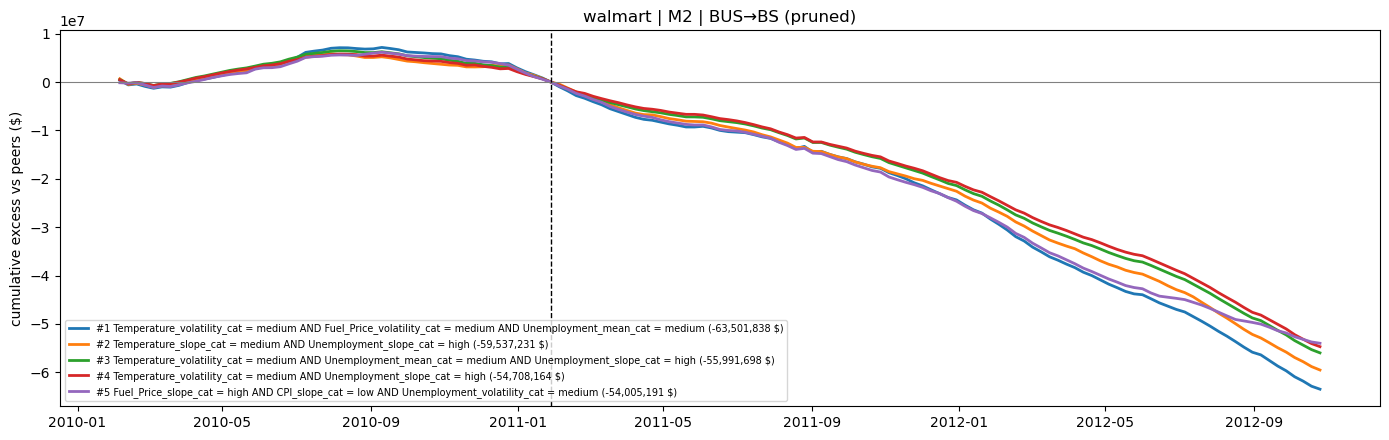

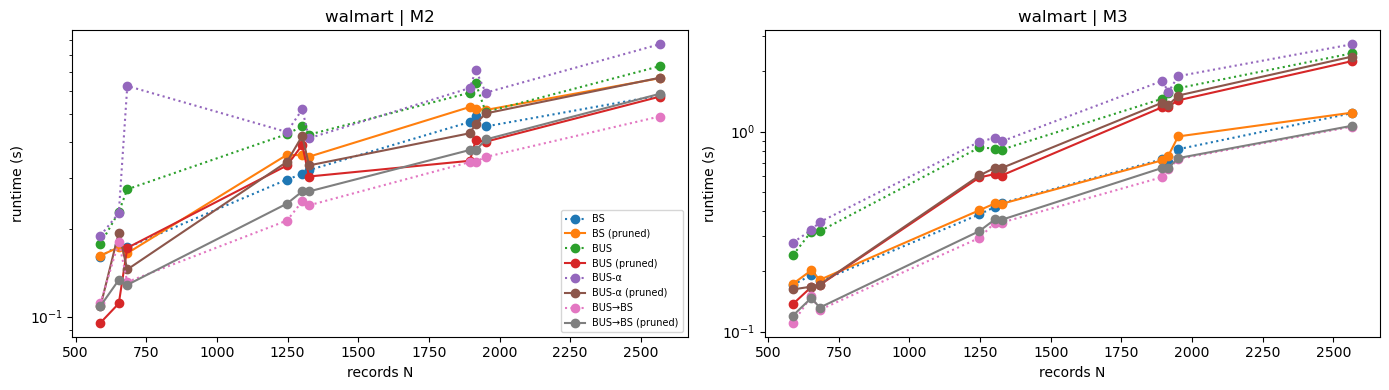

In [12]:
def plot_cumulative_excess(top, phi, k=5, title=""):
    """Running total of each subgroup's relative excess. A steady slope = persistent, subtle deviation;
    a jump = one event. Dashed line = end of the base window."""
    total_excess = excess.sum(axis=0)
    total_level = level.sum()
    fig, ax = plt.subplots(figsize=(14, 4.5))
    for r, (quality, desc, mask) in enumerate(top[:k]):
        E_s = excess[mask].sum(axis=0)
        level_s = level[mask].sum()
        E_s = E_s - level_s * (total_excess - E_s) / (total_level - level_s)
        ax.plot(dates, np.cumsum(E_s), lw=2, label=f"#{r+1} {describe(desc)} ({phi.signed(mask):+,.0f} {UNIT})")
    ax.axhline(0, color="grey", lw=0.8)
    ax.axvline(dates[BASE_LEN - 1], color="black", ls="--", lw=1)
    ax.set_ylabel(f"cumulative excess vs peers ({UNIT})")
    ax.set_title(title)
    ax.legend(fontsize=7, loc="best")
    plt.tight_layout()
    plt.show()


top, stats, pool, phi = main_runs[("M2", "BUS→BS", True)]
plot_cumulative_excess(top, phi, title=f"{DATASET} | M2 | BUS→BS (pruned)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, measure in zip(axes, ("M2", "M3")):
    sub = scaling_df[scaling_df["measure"] == measure].groupby(["method", "prune", "N_sub"])["runtime_s"].mean().reset_index()
    for (method, prune), g in sub.groupby(["method", "prune"]):
        ax.plot(g["N_sub"], g["runtime_s"], marker="o", ls="-" if prune else ":", label=f"{method}{' (pruned)' if prune else ''}")
    ax.set_xlabel("records N")
    ax.set_ylabel("runtime (s)")
    ax.set_title(f"{DATASET} | {measure}")
    ax.set_yscale("log")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()